#**Практическое задание №1**

Установка необходимых пакетов:

In [1]:
!pip install -q tqdm
!pip install --upgrade --no-cache-dir gdown

  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2


Монтирование Вашего Google Drive к текущему окружению:

In [81]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Константы, которые пригодятся в коде далее, и ссылки (gdrive идентификаторы) на предоставляемые наборы данных:

In [3]:
EVALUATE_ONLY = False
TEST_ON_LARGE_DATASET = True
TISSUE_CLASSES = ('ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM')
DATASETS_LINKS = {
    'train': '1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi',
    'train_small': '1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR',
    'train_tiny': '1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui',
    'test': '1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr',
    'test_small': '1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI',
    'test_tiny': '1viiB0s041CNsAK4itvX8PnYthJ-MDnQc'
}


Импорт необходимых зависимостей:

In [4]:
!pip install -q timm

In [5]:
from pathlib import Path
import numpy as np
from typing import List
from tqdm.notebook import tqdm
from time import sleep
from PIL import Image
import IPython.display
from sklearn.metrics import balanced_accuracy_score
import gdown

import random
import matplotlib.pyplot as plt
import torch

In [6]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

seed_everything(42)
print('seed зафиксирован')

seed зафиксирован


In [7]:
print("CUDA available", torch.cuda.is_available())
if torch.cuda.is_available():
  print("GPU")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print ("device = ", device)

CUDA available True
GPU
device =  cuda


---
### Класс Dataset

Предназначен для работы с наборами данных, обеспечивает чтение изображений и соответствующих меток, а также формирование пакетов (батчей).

In [8]:
class Dataset:

    def __init__(self, name):
        self.name = name
        self.is_loaded = False
        url = f"https://drive.google.com/uc?export=download&confirm=pbef&id={DATASETS_LINKS[name]}"
        output = f'{name}.npz'
        gdown.download(url, output, quiet=False)
        print(f'Loading dataset {self.name} from npz.')
        np_obj = np.load(f'{name}.npz')
        self.images = np_obj['data']
        self.labels = np_obj['labels']
        self.n_files = self.images.shape[0]
        self.is_loaded = True
        print(f'Done. Dataset {name} consists of {self.n_files} images.')

    def image(self, i):
        # read i-th image in dataset and return it as numpy array
        if self.is_loaded:
            return self.images[i, :, :, :]

    def images_seq(self, n=None):
        # sequential access to images inside dataset (is needed for testing)
        for i in range(self.n_files if not n else n):
            yield self.image(i)

    def random_image_with_label(self):
        # get random image with label from dataset
        i = np.random.randint(self.n_files)
        return self.image(i), self.labels[i]

    def random_batch_with_labels(self, n):
        # create random batch of images with labels (is needed for training)
        indices = np.random.choice(self.n_files, n)
        imgs = [self.image(i) for i in indices]
        labels = np.array([self.labels[i] for i in indices])
        return np.stack(imgs), labels

    def image_with_label(self, i: int):
        # return i-th image with label from dataset
        return self.image(i), self.labels[i]


### Пример использвания класса Dataset
Загрузим обучающий набор данных, получим произвольное изображение с меткой. После чего визуализируем изображение, выведем метку. В будущем, этот кусок кода можно закомментировать или убрать.

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=4774dd5d-cf6b-4d73-a365-65149a0713f1
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:00<00:00, 177MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.

Got numpy array of shape (224, 224, 3), and label with code 1.
Label code corresponds to BACK class.


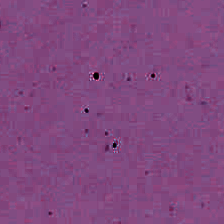

In [9]:
d_train_tiny = Dataset('train_tiny')

img, lbl = d_train_tiny.random_image_with_label()
print()
print(f'Got numpy array of shape {img.shape}, and label with code {lbl}.')
print(f'Label code corresponds to {TISSUE_CLASSES[lbl]} class.')

pil_img = Image.fromarray(img)
IPython.display.display(pil_img)

In [10]:
def describe_dataset(ds):
    print(ds.name)
    print('число картинок:', ds.n_files)
    print('форма images:', ds.images.shape)
    print('форма одной картинки:', ds.images.shape[1:])
    print('тип images:', ds.images.dtype)
    print('min/max:', ds.images.min(), ds.images.max())
    print('размер в памяти, ГБ:', ds.images.nbytes / 1e9)
    print('форма labels:', ds.labels.shape, '| тип:', ds.labels.dtype)

    classes, counts = np.unique(ds.labels, return_counts=True)
    for c, n in zip(classes, counts):
        print(f'  {c} {TISSUE_CLASSES[c]}: {n}')

In [11]:
ds_tiny = Dataset('train_tiny')
describe_dataset(ds_tiny)

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=9e4ee109-bf97-413c-87a8-5ad22eb12bef
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:00<00:00, 199MB/s]


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.
train_tiny
число картинок: 900
форма images: (900, 224, 224, 3)
форма одной картинки: (224, 224, 3)
тип images: uint8
min/max: 0 255
размер в памяти, ГБ: 0.1354752
форма labels: (900,) | тип: uint8
  0 ADI: 100
  1 BACK: 100
  2 DEB: 100
  3 LYM: 100
  4 MUC: 100
  5 MUS: 100
  6 NORM: 100
  7 STR: 100
  8 TUM: 100


In [12]:
ds_train = Dataset('train')
ds_test  = Dataset('test')

describe_dataset(ds_train)
describe_dataset(ds_test)

Downloading...
From (original): https://drive.google.com/uc?id=1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi
From (redirected): https://drive.google.com/uc?id=1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi&confirm=t&uuid=95ae081f-c294-4ff3-b8df-6f24607aa5d9
To: /content/train.npz
100%|██████████| 2.10G/2.10G [00:14<00:00, 145MB/s] 


Loading dataset train from npz.
Done. Dataset train consists of 18000 images.


Downloading...
From (original): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr
From (redirected): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr&confirm=t&uuid=a873d5c6-d623-4cdb-9abb-46fa07343c34
To: /content/test.npz
100%|██████████| 525M/525M [00:06<00:00, 84.4MB/s]


Loading dataset test from npz.
Done. Dataset test consists of 4500 images.
train
число картинок: 18000
форма images: (18000, 224, 224, 3)
форма одной картинки: (224, 224, 3)
тип images: uint8
min/max: 0 255
размер в памяти, ГБ: 2.709504
форма labels: (18000,) | тип: uint8
  0 ADI: 2000
  1 BACK: 2000
  2 DEB: 2000
  3 LYM: 2000
  4 MUC: 2000
  5 MUS: 2000
  6 NORM: 2000
  7 STR: 2000
  8 TUM: 2000
test
число картинок: 4500
форма images: (4500, 224, 224, 3)
форма одной картинки: (224, 224, 3)
тип images: uint8
min/max: 0 255
размер в памяти, ГБ: 0.677376
форма labels: (4500,) | тип: uint8
  0 ADI: 500
  1 BACK: 500
  2 DEB: 500
  3 LYM: 500
  4 MUC: 500
  5 MUS: 500
  6 NORM: 500
  7 STR: 500
  8 TUM: 500


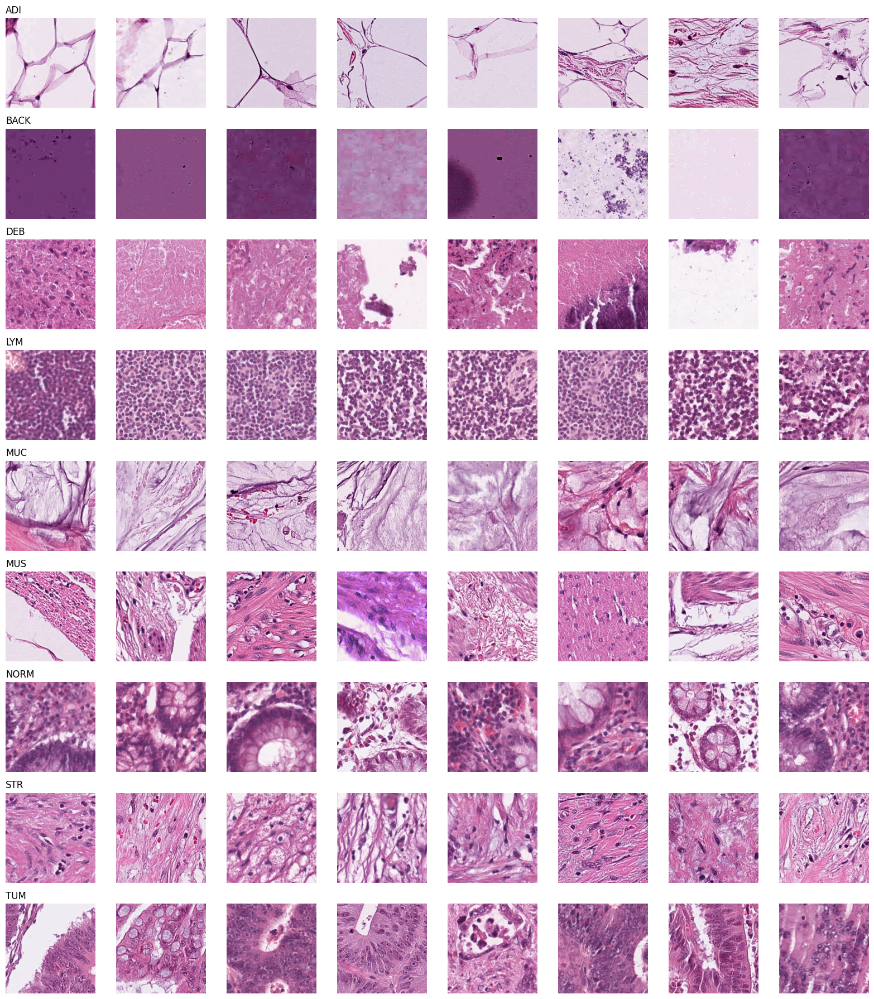

In [13]:
def show_class_grid(ds, n_per_class=8, seed=0):
    rng = np.random.default_rng(seed)
    n_classes = len(TISSUE_CLASSES)
    fig, axes = plt.subplots(n_classes, n_per_class, figsize=(2 * n_per_class, 2 * n_classes))

    for k in range(n_classes):
        idx = np.where(ds.labels == k)[0]
        chosen = rng.choice(idx, n_per_class, replace=False)
        for j, i in enumerate(chosen):
            ax = axes[k, j]
            ax.imshow(ds.images[i]) # картинка с индексом i
            ax.axis('off')
            if j == 0:
                ax.set_title(TISSUE_CLASSES[k], loc='left', fontsize=12)

    plt.tight_layout()
    plt.show()

show_class_grid(ds_train)

In [14]:
def class_color_stats(ds, n_per_class=300, seed=0):
    rng = np.random.default_rng(seed)
    n_classes = len(TISSUE_CLASSES)
    per_image = []
    per_image_labels = []

    for k in range(n_classes):
        idx = np.where(ds.labels == k)[0]
        chosen = rng.choice(idx, min(n_per_class, len(idx)), replace=False)
        imgs = ds.images[chosen]
        m = imgs.mean(axis=(1, 2), dtype=np.float32)# усредняем по высоте и ширине -> (n, 3)
        per_image.append(m)
        per_image_labels.append(np.full(len(chosen), k))

    per_image = np.concatenate(per_image) # (n_classes * n, 3)
    per_image_labels = np.concatenate(per_image_labels)

    class_means = np.stack([per_image[per_image_labels == k].mean(axis=0) for k in range(n_classes)])
    return per_image, per_image_labels, class_means  # class_means: (9, 3)

In [15]:
pi_train, pl_train, cm_train = class_color_stats(ds_train)
pi_test,  pl_test,  cm_test  = class_color_stats(ds_test)

In [16]:
print('класс     train R,G,B     test R,G,B')
for k, name in enumerate(TISSUE_CLASSES):
    print(f'{name:5s}  {cm_train[k].round(1)}   {cm_test[k].round(1)}')

класс     train R,G,B     test R,G,B
ADI    [214.7 193.7 216. ]   [213.7 192.3 215.1]
BACK   [158.8 115.1 160.2]   [163.3 121.7 164.1]
DEB    [192.3 124.6 175.9]   [192.9 124.7 178.6]
LYM    [177.7 127.3 170.3]   [176.3 125.5 169.1]
MUC    [196.6 154.8 192.6]   [197.1 155.  192.7]
MUS    [199.6 131.3 184.1]   [200.5 133.8 184.8]
NORM   [186.5 133.8 176.8]   [187.  134.4 177.3]
STR    [196.8 133.  181.9]   [197.2 133.9 182.4]
TUM    [182.2 123.7 170.5]   [181.4 122.7 169.7]


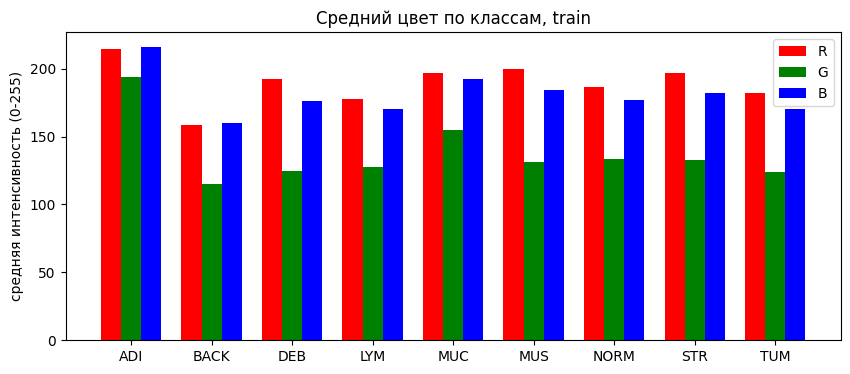

In [17]:
x = np.arange(len(TISSUE_CLASSES))
w = 0.25
plt.figure(figsize=(10, 4))
plt.bar(x - w, cm_train[:, 0], w, color='red', label='R')
plt.bar(x, cm_train[:, 1], w, color='green', label='G')
plt.bar(x + w, cm_train[:, 2], w, color='blue', label='B')
plt.xticks(x, TISSUE_CLASSES)
plt.ylabel('средняя интенсивность (0-255)')
plt.title('Средний цвет по классам, train')
plt.legend()
plt.show()

In [18]:
diff = cm_test - cm_train
print('test - train, по классам (R,G,B):')
for k, name in enumerate(TISSUE_CLASSES):
    print(f'{name:5s}', diff[k].round(1))

test - train, по классам (R,G,B):
ADI   [-1.  -1.4 -0.9]
BACK  [4.5 6.6 3.9]
DEB   [0.7 0.1 2.7]
LYM   [-1.4 -1.8 -1.2]
MUC   [0.4 0.2 0.1]
MUS   [0.9 2.5 0.7]
NORM  [0.5 0.5 0.5]
STR   [0.4 0.9 0.5]
TUM   [-0.9 -1.  -0.8]


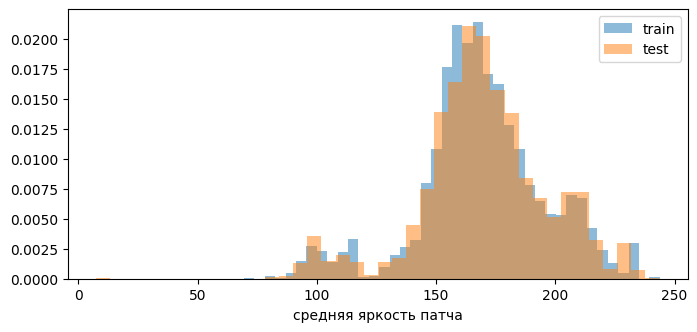

ADI   темных(<30):   0   светлых(>230):   1
BACK  темных(<30):   0   светлых(>230):  33
DEB   темных(<30):   0   светлых(>230):   2
LYM   темных(<30):   0   светлых(>230):   0
MUC   темных(<30):   0   светлых(>230):   0
MUS   темных(<30):   0   светлых(>230):   1
NORM  темных(<30):   0   светлых(>230):   0
STR   темных(<30):   0   светлых(>230):   0
TUM   темных(<30):   0   светлых(>230):   0


In [19]:
bright_train = pi_train.mean(axis=1)
bright_test  = pi_test.mean(axis=1)

plt.figure(figsize=(8, 3.5))
plt.hist(bright_train, bins=40, alpha=0.5, label='train', density=True)
plt.hist(bright_test,  bins=40, alpha=0.5, label='test',  density=True)
plt.xlabel('средняя яркость патча')
plt.legend()
plt.show()


for k, name in enumerate(TISSUE_CLASSES):
    b = bright_train[pl_train == k]
    print(f'{name:5s} темных(<30): {(b < 30).sum():3d}   светлых(>230): {(b > 230).sum():3d}')

In [20]:
# #LBL1: валидация на части обучающей выборки train / val
from sklearn.model_selection import train_test_split

idx_all = np.arange(ds_train.images.shape[0]) # индексы всех 18000 картинок
idx_tr, idx_val = train_test_split(idx_all, test_size=0.15, stratify=ds_train.labels, random_state=42,)

print('train:', len(idx_tr), '| val:', len(idx_val))
print('train по классам:', np.bincount(ds_train.labels[idx_tr]))
print('val   по классам:', np.bincount(ds_train.labels[idx_val]))

train: 15300 | val: 2700
train по классам: [1700 1700 1700 1700 1700 1700 1700 1700 1700]
val   по классам: [300 300 300 300 300 300 300 300 300]


### Обёртка над Dataset для использования с PyTorch

In [21]:
# ============================================================
# (Опционально) Обёртка над Dataset для использования с PyTorch
# ============================================================

# ВНИМАНИЕ:
# Этот код нужен только тем, кто хочет решать задание с помощью PyTorch.
# Он показывает, как "подключить" наш Dataset к torch.utils.data.DataLoader.

try:
    import torch
    from torch.utils.data import Dataset as TorchDataset, DataLoader
    import torchvision.transforms as T
    from PIL import Image

    class HistologyTorchDataset(TorchDataset):
        """
        Обёртка над Dataset для использования с PyTorch.

        base_dataset: экземпляр Dataset('train'), Dataset('train_small'), etc.
        transform:    функция/объект, преобразующий изображение (PIL.Image -> torch.Tensor).

        """
        def __init__(self, base_dataset, transform=None):
            self.base = base_dataset
            # Минимальный transform по умолчанию:
            # np.uint8 [0, 255] -> float32 [0.0, 1.0]
            self.transform = transform or T.ToTensor()

        def __len__(self):
            # Размер датасета
            return len(self.base.images)

        def __getitem__(self, idx):
            """
            Возвращает (image_tensor, label) для PyTorch.
            image_tensor: torch.Tensor формы [3, H, W]
            label: int
            """
            img, label = self.base.image_with_label(idx)  # img: np.ndarray (H, W, 3)
            img = Image.fromarray(img)                    # в PIL.Image
            img = self.transform(img)                     # в torch.Tensor
            return img, int(label)

except ImportError:
    HistologyTorchDataset = None
    print("PyTorch / torchvision не найдены. Обёртка HistologyTorchDataset недоступна.")


### Пример использвания класса HistologyTorchDataset

In [22]:
if "HistologyTorchDataset" not in globals() or HistologyTorchDataset is None:
    print("PyTorch не установлен или обёртка недоступна — пример пропущен.")
else:
    print("Пример использования PyTorch-обёртки над Dataset")

    base_train = Dataset('train_tiny')

    # Создаём PyTorch-совместимый датасет
    train_ds = HistologyTorchDataset(base_train)

    # DataLoader автоматически создаёт батчи и перемешивает данные
    from torch.utils.data import DataLoader
    train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)

    # Берём один батч и выводим информацию
    images_batch, labels_batch = next(iter(train_loader))

    print("Форма батча изображений:", tuple(images_batch.shape))  # [batch, 3, 224, 224]
    print("Форма батча меток:", tuple(labels_batch.shape)) # [batch]
    print("Пример меток:", labels_batch[:10].tolist())

    print("Тип images_batch:", type(images_batch))
    print("Тип labels_batch:", type(labels_batch))


Пример использования PyTorch-обёртки над Dataset


Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=907a39fd-fa29-4e6c-911f-6f0f6902da1f
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:00<00:00, 252MB/s]


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.
Форма батча изображений: (8, 3, 224, 224)
Форма батча меток: (8,)
Пример меток: [3, 0, 2, 2, 3, 8, 4, 7]
Тип images_batch: <class 'torch.Tensor'>
Тип labels_batch: <class 'torch.Tensor'>


In [23]:
from torch.utils.data import Subset, DataLoader

train_wrap = HistologyTorchDataset(ds_train)
val_wrap = HistologyTorchDataset(ds_train)

train_ds = Subset(train_wrap, idx_tr)
val_ds = Subset(val_wrap, idx_val)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

print('картинок train/val:', len(train_ds), len(val_ds))
print('батчей train/val:', len(train_loader), len(val_loader))

картинок train/val: 15300 2700
батчей train/val: 239 22


images: torch.Size([64, 3, 224, 224]) torch.float32
labels: torch.Size([64]) torch.int64
диапазон значений: 0.0 1.0
средний RGB по батчу: tensor([0.7327, 0.5271, 0.7020])
классы в батче: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8])


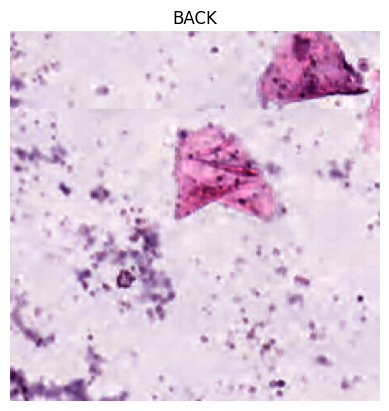

In [24]:
images, labels = next(iter(train_loader))

print('images:', images.shape, images.dtype)
print('labels:', labels.shape, labels.dtype)
print('диапазон значений:', images.min().item(), images.max().item())
print('средний RGB по батчу:', images.mean(dim=(0, 2, 3)))
print('классы в батче:', labels.unique())

# Посмотрим одну картинку
img = images[0].permute(1, 2, 0).numpy()
plt.imshow(img)
plt.title(TISSUE_CLASSES[labels[0]])
plt.axis('off')
plt.show()

In [25]:
import torchvision.transforms as T

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
# PIL (H,W,C, uint8) -> тензор (C,H,W), float [0,1]
val_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), # вычесть mean, поделить на std
])

In [26]:
def make_loaders(train_tf, val_tf, batch_size=64):
    train_wrap = HistologyTorchDataset(ds_train, transform=train_tf) # transform для обучения
    val_wrap = HistologyTorchDataset(ds_train, transform=val_tf) # transform для валидации

    train_ds = Subset(train_wrap, idx_tr)
    val_ds = Subset(val_wrap,   idx_val)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=2 * batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader

train_loader, val_loader = make_loaders(val_tf, val_tf)
print(len(train_loader), len(val_loader))

239 22


min/max: -2.1179039478302 2.640000104904175
средний по каналам: tensor([1.1346, 0.4052, 1.3758])
std по каналам: tensor([0.6952, 0.9608, 0.6855])


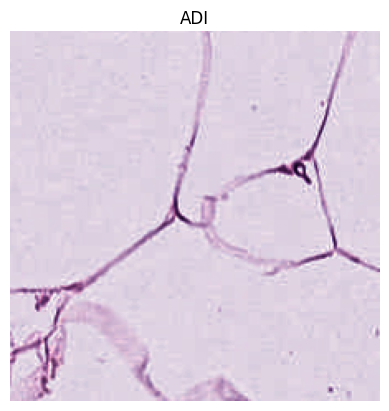

In [27]:
def denormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1)

images, labels = next(iter(train_loader))
print('min/max:', images.min().item(), images.max().item())
print('средний по каналам:', images.mean(dim=(0, 2, 3)))
print('std по каналам:', images.std(dim=(0, 2, 3)))

img = denormalize(images[0]).permute(1, 2, 0).numpy()
plt.imshow(img)
plt.title(TISSUE_CLASSES[labels[0]])
plt.axis('off')
plt.show()

Аугментация

In [28]:
# #LBL11: аугментация
# случайный поворот на 0/90/180/270 градусов
class RandomRot90:
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k)

In [29]:
train_tf = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    RandomRot90(),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.05),
    T.RandomApply([T.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.2),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

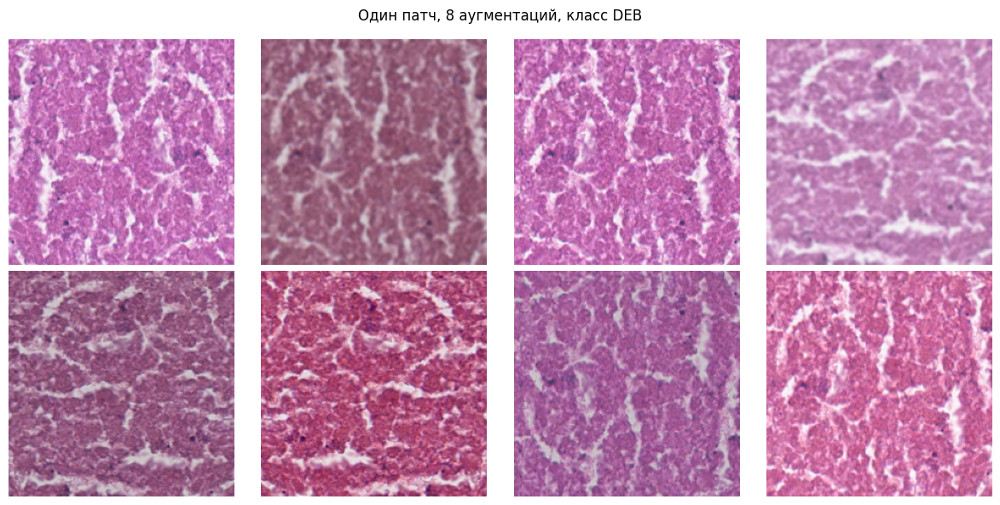

In [30]:
i = idx_tr[0]
pil = Image.fromarray(ds_train.images[i])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    t = train_tf(pil)
    ax.imshow(denormalize(t).permute(1, 2, 0).numpy())
    ax.axis('off')
fig.suptitle(f'Один патч, 8 аугментаций, класс {TISSUE_CLASSES[ds_train.labels[i]]}')
plt.tight_layout()
plt.show()

In [31]:
import time

train_loader, val_loader = make_loaders(train_tf=train_tf, val_tf=val_tf)

t0 = time.time()
for b, (x, y) in enumerate(train_loader):
    if b == 20:
        break
dt = time.time() - t0
print(f'20 батчей за {dt:.1f} с -> эпоха (239 батчей) => примерно {dt / 20 * 239 / 60:.1f} мин')

20 батчей за 5.8 с -> эпоха (239 батчей) => примерно 1.2 мин


In [32]:
# #LBL11: аугментация
# случайное изменение карт красителей
from skimage.color import rgb2hed, hed2rgb

class HEDJitter:
    def __init__(self, sigma=0.05, p=0.8):
        self.sigma = sigma
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img
        arr = np.asarray(img)
        hed = rgb2hed(arr)
        alpha = np.random.uniform(1 - self.sigma, 1 + self.sigma, size=3)
        beta  = np.random.uniform(-self.sigma, self.sigma, size=3)
        out = hed2rgb(hed * alpha + beta)
        return Image.fromarray((np.clip(out, 0, 1) * 255).astype(np.uint8))

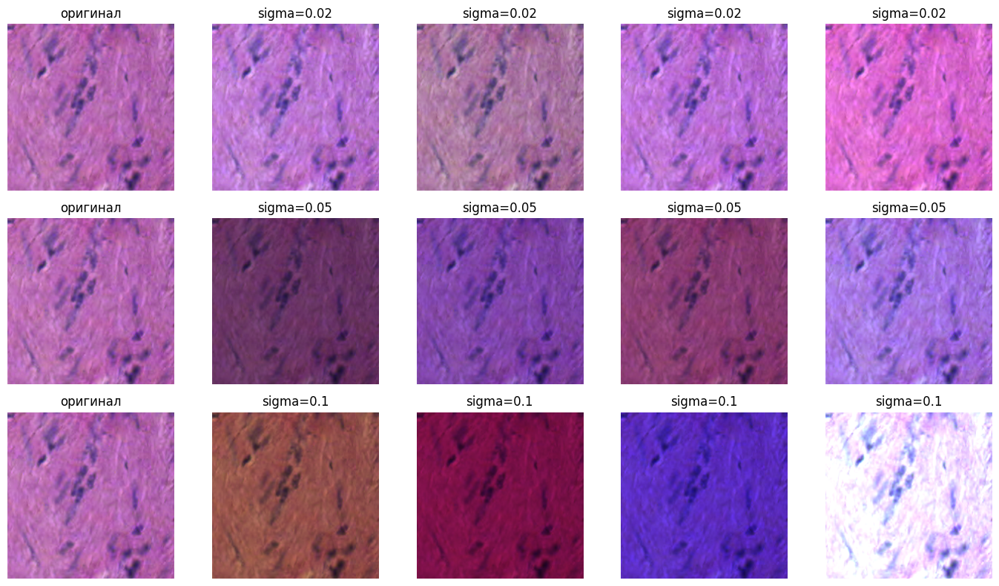

In [33]:
i = idx_tr[5]
pil = Image.fromarray(ds_train.images[i])
sigmas = [0.02, 0.05, 0.10]

fig, axes = plt.subplots(len(sigmas), 5, figsize=(14, 8))
for r, s in enumerate(sigmas):
    aug = HEDJitter(sigma=s, p=1.0)
    axes[r, 0].imshow(pil)
    axes[r, 0].set_title('оригинал')
    for c in range(1, 5):
        axes[r, c].imshow(aug(pil))
        axes[r, c].set_title(f'sigma={s}')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [34]:
# #LBL11: итоговая цепочка аугментаций для обучения
# в первый раз сигма была меньше, сделал чтобы меньше цеплялась за окраску
SIGMA_HED = 0.08


train_tf = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    RandomRot90(),
    HEDJitter(sigma=SIGMA_HED, p=0.8),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
    T.RandomApply([T.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.2),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_loader, val_loader = make_loaders(train_tf, val_tf)

In [35]:
t0 = time.time()
for b, (x, y) in enumerate(train_loader):
    if b == 20:
        break
dt = time.time() - t0
print(f'20 батчей за {dt:.1f} с -> эпоха примерно {dt / 20 * 239 / 60:.1f} мин')

20 батчей за 8.5 с -> эпоха примерно 1.7 мин


### Обоснование выбора аугментаций `#LBL11`

Во время EDA мы увидели две вещи: (1) средний цвет частично выдаёт класс (ADI и MUC заметно светлее и бледнее остальных), (2) `train` и `test` почти идентичны по цвету, а скрытые тестовые наборы, скорее всего, окрашены и оцифрованы иначе. Поэтому аугментации нацелены на то, чтобы сеть училась **текстуре и структуре ткани**, а не цвету:

| Аугментация | Зачем |
|---|---|
| Отражения (по горизонтали и вертикали) и повороты на 0/90/180/270° | У ткани нет выделенного направления; повороты на кратные 90° не создают пустых краёв |
| `HEDJitter` (случайное изменение карт гематоксилина и эозина) | Имитирует разные пропорции красителей в разных лабораториях, самый реалистичный сдвиг домена |
| `ColorJitter` (слабый) | Небольшие колебания яркости, контраста, насыщенности, оттенка (сканер, экспозиция) |
| `GaussianBlur` (с вероятностью 0.2) | Нерезкие участки слайда |

Масштабирование и сильные кропы не используются: размер ядер несёт диагностическую информацию, а увеличение у всех патчей одинаковое.

Ещё в обучении используется **MixUp / CutMix** (в половине батчей): две картинки смешиваются, а loss считается по обеим меткам. Это тоже синтетическое расширение набора данных, оно мешает сети запоминать отдельные патчи и помогает на похожих классах (STR и MUS).

In [36]:
# #LBL13: искажения валидации для оценки устойчивости
import io
import torchvision.transforms.functional as TF

def jpeg_compress(img, quality=40):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0) # вернуться в начало «файла»
    return Image.open(buf).convert('RGB')

class HEDShift:
    # Детерминированный сдвиг красителей
    def __init__(self, alpha, beta):
        self.alpha = np.array(alpha)
        self.beta  = np.array(beta)
    def __call__(self, img):
        hed = rgb2hed(np.asarray(img))
        out = hed2rgb(hed * self.alpha + self.beta)
        return Image.fromarray((np.clip(out, 0, 1) * 255).astype(np.uint8))

STRESS = {
    'hue': lambda im: TF.adjust_hue(im, 0.05),
    'gamma': lambda im: TF.adjust_gamma(im, 1.4),
    'blur': lambda im: TF.gaussian_blur(im, kernel_size=7, sigma=1.5),
    'jpeg': lambda im: jpeg_compress(im, 40),
    'hed': HEDShift(alpha=[1.1, 0.9, 1.0], beta=[0.03, -0.03, 0.0]),
}

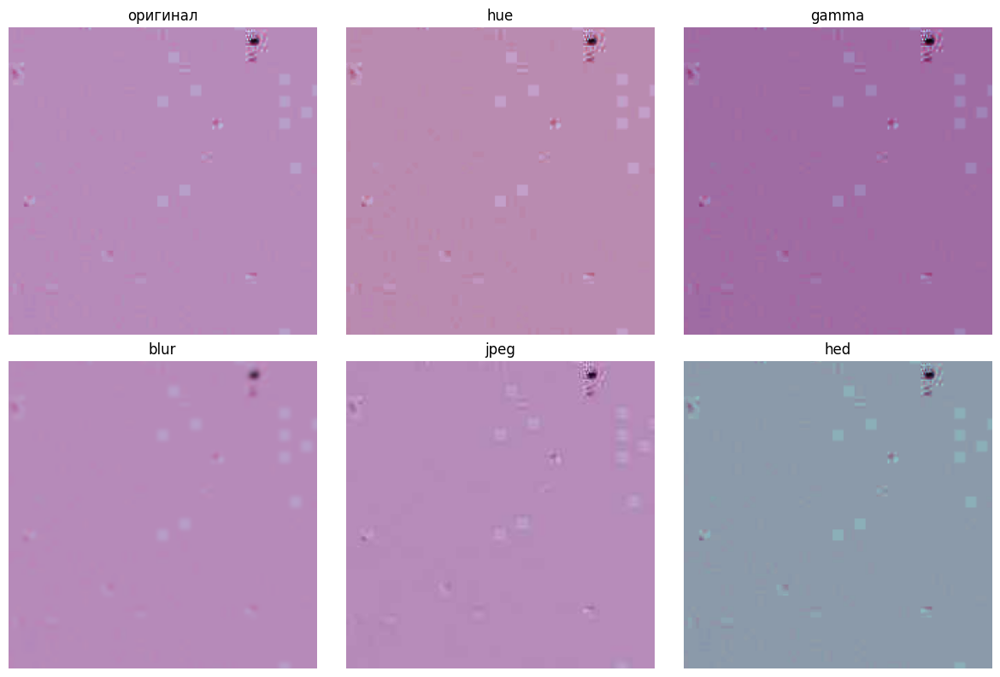

In [37]:
i = idx_val[3]
pil = Image.fromarray(ds_train.images[i])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(pil)
axes[0, 0].set_title('оригинал')
for ax, (name, fn) in zip(axes.flat[1:], STRESS.items()):
    ax.imshow(fn(pil)) # применить искажение
    ax.set_title(name)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [38]:
def make_eval_loader(pre_tf=None, batch_size=128):
    steps = ([pre_tf] if pre_tf is not None else []) + [T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    wrap = HistologyTorchDataset(ds_train, transform=T.Compose(steps))
    return DataLoader(Subset(wrap, idx_val), batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

val_clean_loader = make_eval_loader()
stress_loaders = {name: make_eval_loader(T.Lambda(fn) if not callable(fn) else fn) for name, fn in STRESS.items()}
print(list(stress_loaders))

['hue', 'gamma', 'blur', 'jpeg', 'hed']


In [39]:
x_clean, y_clean = next(iter(val_clean_loader))
for name, loader in stress_loaders.items():
    x_s, y_s = next(iter(loader))
    same_labels = bool((y_s == y_clean).all())
    diff = (x_s - x_clean).abs().mean().item()
    print(f'{name:6s} метки совпадают: {same_labels} | средняя разница: {diff:.3f}')

hue    метки совпадают: True | средняя разница: 0.085
gamma  метки совпадают: True | средняя разница: 0.365
blur   метки совпадают: True | средняя разница: 0.168
jpeg   метки совпадают: True | средняя разница: 0.103
hed    метки совпадают: True | средняя разница: 0.442


Обычная валидация соседние патчи с одного препарата попадают и в обучение, и в проверку, а цвет и сжатие те же.
Мы заранее строим **детерминированные искажённые копии валидации** (сдвиг оттенка, гамма, размытие, JPEG, сдвиг красителей) и выбираем модель по критерию `score = 0.5 · bacc(clean) + 0.5 · среднее bacc(стресс-наборов)`. Так отбираются эпохи и гиперпараметры, устойчивые к смене домена, а не только хорошие на «чистых» данных.

In [40]:
import torch.nn as nn
from sklearn.metrics import accuracy_score, balanced_accuracy_score

@torch.no_grad() #без градиентов
def predict(model, loader, device):
    model.eval() # режим оценки
    all_preds, all_labels = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        all_preds.append(logits.argmax(dim=1).cpu()) # класс с максимальным логитом
        all_labels.append(y)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def evaluate(model, loader, device):
    preds, labels = predict(model, loader, device)
    return accuracy_score(labels, preds), balanced_accuracy_score(labels, preds)

In [41]:
def evaluate_all(model, device, verbose=True):
    results = {}
    results['clean'] = evaluate(model, val_clean_loader, device)
    for name, loader in stress_loaders.items():
        results[name] = evaluate(model, loader, device)
    if verbose:
        print(f'{"набор":8s} {"acc":>7s} {"bacc":>7s}')
        for name, (acc, bacc) in results.items():
            print(f'{name:8s} {acc:7.4f} {bacc:7.4f}')
    return results

In [42]:
dummy = nn.Sequential(
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(3, 9)
).to(device)

t0 = time.time()
res = evaluate_all(dummy, device)
print(f'время оценки по 6 наборам: {time.time() - t0:.1f} с')

набор        acc    bacc
clean     0.1111  0.1111
hue       0.1111  0.1111
gamma     0.1274  0.1274
blur      0.1111  0.1111
jpeg      0.1111  0.1111
hed       0.1137  0.1137
время оценки по 6 наборам: 29.0 с


In [43]:
import timm

PRETRAINED = True
NUM_CLASSES = len(TISSUE_CLASSES)

model = timm.create_model('efficientnet_b0', pretrained=PRETRAINED, num_classes=NUM_CLASSES)
model = model.to(device)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

In [44]:
n_params = sum(p.numel() for p in model.parameters())
print(f'параметров: {n_params / 1e6:.2f} млн')

print('mean timm:', model.pretrained_cfg['mean'])
print('std  timm:', model.pretrained_cfg['std'])
print('наши константы:', IMAGENET_MEAN, IMAGENET_STD)

параметров: 4.02 млн
mean timm: (0.485, 0.456, 0.406)
std  timm: (0.229, 0.224, 0.225)
наши константы: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]


In [45]:
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

model.eval() # режим оценки
with torch.no_grad():
    logits = model(x)
loss = nn.CrossEntropyLoss()(logits, y)

print('форма логитов:', logits.shape)
print('начальная loss:', loss.item(), '| ln(9) =', float(np.log(9)))

форма логитов: torch.Size([64, 9])
начальная loss: 4.299962043762207 | ln(9) = 2.1972245773362196


In [46]:
t0 = time.time()
base_results = evaluate_all(model, device)
print(f'время оценки: {time.time() - t0:.1f} с')

набор        acc    bacc
clean     0.0741  0.0741
hue       0.0733  0.0733
gamma     0.0844  0.0844
blur      0.0800  0.0800
jpeg      0.0648  0.0648
hed       0.0596  0.0596
время оценки: 34.7 с


In [47]:
EPOCHS = 15
MAX_LR = 1e-3
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.1
MIX_PROB = 0.5 # в половине батчей делаем mixup или cutmix
SEEDS = [42, 7, 2026] # сколько seed, столько моделей в ансамбле

---
## Обучение модели

Ниже собрана вся инфраструктура обучения. Метки `#LBLn` соответствуют номерам пунктов таблицы «Дополнения» из условия задания (расшифровка в `README.md`).

In [48]:
import copy, csv, json
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

ARCH = 'efficientnet_b0'

# Папка для чекпоинтов и результатов: на Google Drive, для перезапуска Colab
BASE_DIR = Path('/content/drive/MyDrive/prak_nn_1')
CKPT_DIR = BASE_DIR / 'ckpt'
RESULTS_DIR = BASE_DIR / 'results'
for _d in (CKPT_DIR, RESULTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print('чекпоинты:', CKPT_DIR)
print('результаты:', RESULTS_DIR)


def build_net(pretrained: bool):
    #EfficientNet-B0 на 9 классов
    return timm.create_model(ARCH, pretrained=pretrained, num_classes=NUM_CLASSES).to(device)

чекпоинты: /content/drive/MyDrive/prak_nn_1/ckpt
результаты: /content/drive/MyDrive/prak_nn_1/results


In [49]:
class SubDataset:
    def __init__(self, base, indices, name=None):
        indices = np.asarray(indices)
        self.name = name or f'{base.name}_sub{len(indices)}'
        self.images = base.images[indices]
        self.labels = base.labels[indices]
        self.n_files = len(indices)
        self.is_loaded = True

    def image(self, i):
        return self.images[i]

    def images_seq(self, n=None):
        for i in range(self.n_files if not n else n):
            yield self.image(i)

    def image_with_label(self, i):
        return self.image(i), self.labels[i]


def _make_eval_loader(dataset, idx, pre_tf=None, batch_size=128, num_workers=2):
    # Loader без случайных аугментаций
    # pre_tf - детерминированное искажение (для стресс-наборов)
    steps = ([pre_tf] if pre_tf is not None else []) + [T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    wrap = HistologyTorchDataset(dataset, transform=T.Compose(steps))
    return DataLoader(Subset(wrap, [int(i) for i in idx]), batch_size=batch_size, shuffle=False,
                      num_workers=num_workers, pin_memory=torch.cuda.is_available())


def make_split_loaders(dataset, batch_size=64, val_fraction=0.15, stress_n=1000, seed=42, num_workers=2):
    # #LBL1: разбиение на train/val.
    # Возвращает train_loader (с аугментациями)
    # вся валидация и стресс-наборы (первые stress_n картинок валидации).
    # если val_fraction=0, то учимся на всех картинках и валидации нет
    idx_all = np.arange(dataset.n_files)
    if val_fraction > 0:
        idx_tr, idx_val = train_test_split(idx_all, test_size=val_fraction,
                                           stratify=dataset.labels, random_state=seed)
    else:
        idx_tr, idx_val = idx_all, []
    train_wrap = HistologyTorchDataset(dataset, transform=train_tf)
    train_loader = DataLoader(Subset(train_wrap, [int(i) for i in idx_tr]), batch_size=batch_size,
                              shuffle=True, num_workers=num_workers,
                              pin_memory=torch.cuda.is_available(), drop_last=True)
    eval_loaders = {}
    if len(idx_val) > 0:
        eval_loaders['clean'] = _make_eval_loader(dataset, idx_val, None, 2 * batch_size, num_workers)
        for name, fn in STRESS.items():
            eval_loaders[name] = _make_eval_loader(dataset, idx_val[:stress_n], fn, 2 * batch_size, num_workers)
    return train_loader, eval_loaders


def make_monitor_loader(dataset, per_class=90, seed=0):
    # #LBL7: небольшая часть тестового набора для мониторинга после каждой эпохи
    #только для вывода, на выбор модели не влияет.
    rng = np.random.default_rng(seed)
    idx = np.concatenate([
        rng.choice(np.where(dataset.labels == k)[0],
                   min(per_class, int((dataset.labels == k).sum())), replace=False)
        for k in range(NUM_CLASSES)])
    return _make_eval_loader(dataset, idx, None, 128, 2)

In [50]:
def evaluate_loaders(model, loaders, device, verbose=True):
    #Оценка модели по словарю loader'ов: {имя: (accuracy, balanced accuracy)}
    results = {name: evaluate(model, loader, device) for name, loader in loaders.items()}
    if verbose:
        print(f'{"набор":8s} {"acc":>7s} {"bacc":>7s}')
        for name, (acc, bacc) in results.items():
            print(f'{name:8s} {acc:7.4f} {bacc:7.4f}')
    return results


def robust_score(results):
    # #LBL13: критерий выбора модели = 0.5 * bacc(clean) + 0.5 * средняя bacc по стресс-наборам.
    clean = results['clean'][1]
    stress = [v[1] for k, v in results.items() if k != 'clean']
    return 0.5 * clean + 0.5 * float(np.mean(stress)) if stress else clean

In [51]:
def make_training_objects(model, steps_per_epoch, epochs, max_lr, weight_decay, label_smoothing):
    #Функция потерь, оптимизатор, расписание lr и скейлер для смешанной точности.
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lr, epochs=epochs, steps_per_epoch=steps_per_epoch, pct_start=0.2)
    try:
        scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
    except AttributeError: # для старой версии torch
        scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
    return criterion, optimizer, scheduler, scaler


def mix_batch(x, y):
    # #LBL11: mixup / cutmix, смешиваем батч с его же перемешанной копией
    # возвращаю картинки, обе метки и долю первой картинки (lam)
    perm = torch.randperm(x.size(0), device=x.device)
    if random.random() < 0.5:
        # mixup: просто складываем две картинки с весами
        lam = float(np.random.beta(0.2, 0.2))
        x = lam * x + (1 - lam) * x[perm]
    else:
        # cutmix: вставляем прямоугольник из другой картинки
        lam = float(np.random.beta(1.0, 1.0))
        H, W = x.shape[2], x.shape[3]
        r = np.sqrt(1 - lam)
        h, w = int(H * r), int(W * r)
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2 = max(cy - h // 2, 0), min(cy + h // 2, H)
        x1, x2 = max(cx - w // 2, 0), min(cx + w // 2, W)
        x = x.clone()
        x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W) # настоящая доля после обрезки по краям
    return x, y, y[perm], lam


def train_one_epoch(model, loader, criterion, optimizer, scheduler, scaler, device, max_batches=None, mix_prob=0.0):
    #Одна эпоха обучения (смешанная точность, обрезка градиента)
    # возвращает (loss, accuracy)
    model.train()
    use_amp = device.type == 'cuda'
    total_loss, correct, seen = 0.0, 0, 0
    for b, (x, y) in enumerate(tqdm(loader, leave=False)):
        if max_batches is not None and b >= max_batches:
            break
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        y2, lam = y, 1.0
        if random.random() < mix_prob:
            x, y, y2, lam = mix_batch(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
            # для смешанного батча loss считается по обеим меткам
            loss = lam * criterion(logits, y) + (1 - lam) * criterion(logits, y2)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item() * x.size(0)
        # на смешанных батчах точность считаю по "главной" метке
        y_main = y if lam >= 0.5 else y2
        correct += (logits.argmax(dim=1) == y_main).sum().item()
        seen += x.size(0)
    return total_loss / seen, correct / seen

In [52]:
def fit(model, train_loader, eval_loaders, epochs=EPOCHS, max_lr=MAX_LR, weight_decay=WEIGHT_DECAY,
        label_smoothing=LABEL_SMOOTHING, ckpt_dir=None, monitor_loader=None, resume=False,
        max_batches=None, verbose=True, mix_prob=MIX_PROB):
    #Цикл обучения по эпохам.
    # #LBL3: автосохранение: best.pt (лучшая по robust_score) и last.pt после каждой эпохи
    # #LBL4: веса каждой эпохи: epoch_N.pt (загрузка: Model.load_checkpoint(N))
    # #LBL5: вывод метрик после каждой эпохи
    # #LBL7: автотестирование на части тестового набора после каждой эпохи (monitor_loader)
    # #LBL12: возобновление обучения после прерывания (resume=True)
    # если eval_loaders пустой (учимся на всех данных), то лучшей считается последняя эпоха

    criterion, optimizer, scheduler, scaler = make_training_objects(
        model, len(train_loader), epochs, max_lr, weight_decay, label_smoothing)
    history = {'epoch': [], 'train_loss': [], 'train_acc': [], 'lr': [],
               'val': [], 'score': [], 'monitor': [], 'sec': []}
    start_epoch, best_score, best_state = 0, -1.0, None
    ckpt_dir = Path(ckpt_dir) if ckpt_dir is not None else None
    if ckpt_dir is not None:
        ckpt_dir.mkdir(parents=True, exist_ok=True)

    # #LBL12: если колаб упал, продолжаем с последней сохраненной эпохи
    if resume and ckpt_dir is not None and (ckpt_dir / 'last.pt').exists():
        state = torch.load(ckpt_dir / 'last.pt', map_location=device, weights_only=False)
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        scaler.load_state_dict(state['scaler'])
        history, start_epoch, best_score = state['history'], state['epoch'] + 1, state['best_score']
        print(f'Возобновляю обучение с эпохи {start_epoch + 1} из {epochs}')

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scheduler, scaler,
                                          device, max_batches, mix_prob)
        # #LBL1: валидация (чистая + стресс-наборы)
        res = evaluate_loaders(model, eval_loaders, device, verbose=False)
        score = robust_score(res) if res else None
        # #LBL7: тест на части тестового набора после эпохи
        mon = evaluate(model, monitor_loader, device) if monitor_loader is not None else None
        lr_now = optimizer.param_groups[0]['lr']
        sec = time.time() - t0

        history['epoch'].append(epoch + 1)
        history['train_loss'].append(float(tr_loss))
        history['train_acc'].append(float(tr_acc))
        history['lr'].append(float(lr_now))
        history['val'].append({k: [float(v[0]), float(v[1])] for k, v in res.items()})
        history['score'].append(None if score is None else float(score))
        history['monitor'].append(None if mon is None else [float(mon[0]), float(mon[1])])
        history['sec'].append(float(sec))

        # #LBL5: печать показателей
        if verbose:
            val_txt = ''
            if res:
                stress_mean = float(np.mean([v[1] for k, v in res.items() if k != 'clean']))
                val_txt = f' | val bacc {res["clean"][1]:.4f} | stress bacc {stress_mean:.4f} | score {score:.4f}'
            mon_txt = '' if mon is None else f' | test-monitor acc {mon[0]:.4f}'
            print(f'эпоха {epoch + 1:2d}/{epochs} | loss {tr_loss:.4f} | train acc {tr_acc:.4f}'
                  f'{val_txt}{mon_txt} | lr {lr_now:.2e} | {sec:.0f} с')

        is_best = score is None or score > best_score
        if is_best:
            best_score = best_score if score is None else score
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ckpt_dir is not None:
            torch.save(model.state_dict(), ckpt_dir / f'epoch_{epoch + 1}.pt') # #LBL4
            if is_best:
                torch.save(best_state, ckpt_dir / 'best.pt') # #LBL3
            torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                        'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                        'history': history, 'epoch': epoch, 'best_score': best_score},
                       ckpt_dir / 'last.pt')

    # в конце возвращаем лучшие по robust_score веса
    if ckpt_dir is not None and (ckpt_dir / 'best.pt').exists():
        model.load_state_dict(torch.load(ckpt_dir / 'best.pt', map_location=device, weights_only=True))
    elif best_state is not None:
        model.load_state_dict(best_state)
    return history

In [53]:
def plot_history(history, save_path=None):
    # #LBL6: графики процесса обучения.
    ep = history['epoch']
    val = history['val']
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))

    axes[0, 0].plot(ep, history['train_loss'], 'o-')
    axes[0, 0].set_title('Функция потерь (train)')
    axes[0, 0].set_xlabel('эпоха')

    axes[0, 1].plot(ep, history['train_acc'], 'o-', label='train acc (с аугментациями)')
    axes[0, 1].plot(ep, [v['clean'][0] for v in val], 'o-', label='val acc (clean)')
    axes[0, 1].plot(ep, [v['clean'][1] for v in val], 's--', label='val bacc (clean)')
    if history['monitor'] and history['monitor'][0] is not None:
        axes[0, 1].plot(ep, [m[0] for m in history['monitor']], '^-', label='test acc (монитор)')
    axes[0, 1].set_title('Точность')
    axes[0, 1].set_xlabel('эпоха')
    axes[0, 1].legend()

    stress_names = [k for k in val[0] if k != 'clean']
    axes[1, 0].plot(ep, [v['clean'][1] for v in val], 'k-o', label='clean', linewidth=2)
    for name in stress_names:
        axes[1, 0].plot(ep, [v[name][1] for v in val], 'o-', label=name)
    axes[1, 0].set_title('Balanced accuracy на стресс-наборах')
    axes[1, 0].set_xlabel('эпоха')
    axes[1, 0].legend()

    axes[1, 1].plot(ep, history['lr'], 'o-')
    axes[1, 1].set_title('Learning rate (в конце эпохи)')
    axes[1, 1].set_xlabel('эпоха')

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    plt.show()


def load_history():
   #История обучения из last.pt
    p = CKPT_DIR / 'm0' / 'last.pt'
    if p.exists():
        return torch.load(p, map_location='cpu', weights_only=False)['history']
    return None

In [54]:
def sensitivity_specificity(y_true, y_pred, n_classes=None):
    # #LBL8: матрица ошибок, чувствительность и специфичность по каждому классу (один против остальных)
    n_classes = n_classes or NUM_CLASSES
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    total = cm.sum()
    rows = []
    for k in range(n_classes):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = total - tp - fn - fp
        sens = tp / (tp + fn) if (tp + fn) else float('nan')
        spec = tn / (tn + fp) if (tn + fp) else float('nan')
        rows.append((TISSUE_CLASSES[k], float(sens), float(spec)))
    return cm, rows


def print_sens_spec(rows):
    print(f'{"класс":6s} {"чувствит.":>10s} {"специфич.":>10s}')
    for name, sens, spec in rows:
        print(f'{name:6s} {sens:10.4f} {spec:10.4f}')
    print(f'{"среднее":6s} {np.nanmean([r[1] for r in rows]):10.4f} {np.nanmean([r[2] for r in rows]):10.4f}')


def plot_confusion(cm, save_path=None, title='Матрица ошибок (строки - истинные классы)'):
    n = cm.shape[0]
    cmn = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n))
    ax.set_xticklabels(TISSUE_CLASSES, rotation=45)
    ax.set_yticks(range(n))
    ax.set_yticklabels(TISSUE_CLASSES)
    ax.set_xlabel('предсказано')
    ax.set_ylabel('истина')
    ax.set_title(title)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{cm[i, j]}', ha='center', va='center', fontsize=8,
                    color='white' if cmn[i, j] > 0.5 else 'black')
    fig.colorbar(im)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    plt.show()


def save_predictions_csv(path, y_true, y_pred):
    # #LBL10: сохранение результатов тестирования в csv
    with open(path, 'w', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        w.writerow(['index', 'true', 'pred', 'true_name', 'pred_name'])
        for i, (t, p) in enumerate(zip(y_true, y_pred)):
            w.writerow([i, int(t), int(p), TISSUE_CLASSES[int(t)], TISSUE_CLASSES[int(p)]])
    print('предсказания сохранены:', path)


def show_errors(dataset, y_true, y_pred, save_path=None, n=16, seed=0):
    # #LBL10: визуализация ошибочно классифицированных патчей (истина => предсказание)
    y_pred = np.asarray(y_pred)
    y_true = np.asarray(y_true)[:len(y_pred)]
    wrong = np.where(y_true != y_pred)[0]
    print(f'ошибок: {len(wrong)} из {len(y_true)}')
    if len(wrong) == 0:
        return
    rng = np.random.default_rng(seed)
    chosen = rng.choice(wrong, min(n, len(wrong)), replace=False)
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, chosen):
        ax.imshow(dataset.image(int(i)))
        ax.set_title(f'{TISSUE_CLASSES[y_true[i]]} -> {TISSUE_CLASSES[y_pred[i]]}', fontsize=10, color='red')
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
        print('картинка с ошибками сохранена:', save_path)
    plt.show()

In [55]:
# Быстрая проверка всего цикла обучения на train_tiny (5 батчей, 1 эпоха) на копии модели.
# при EVALUATE_ONLY пропускаем, там обучение не нужно
if not EVALUATE_ONLY:
    smoke_train, smoke_eval = make_split_loaders(ds_tiny, batch_size=32, stress_n=100)
    smoke_model = copy.deepcopy(model)
    t0 = time.time()
    smoke_hist = fit(smoke_model, smoke_train, smoke_eval, epochs=1, max_batches=5, ckpt_dir=None)
    print(f'smoke-test пройден за {time.time() - t0:.0f} с')
    del smoke_model, smoke_train, smoke_eval

  0%|          | 0/23 [00:00<?, ?it/s]

/tmp/ipykernel_539/354854754.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


эпоха  1/1 | loss 4.3481 | train acc 0.1437 | val bacc 0.1778 | stress bacc 0.2042 | score 0.1910 | lr 9.86e-04 | 43 с
smoke-test пройден за 43 с


In [56]:
HPARAM_GRID = [{'max_lr': 3e-4}, {'max_lr': 1e-3}, {'max_lr': 3e-3}]


def select_hparams(dataset, grid=HPARAM_GRID, epochs=2, per_class=500, seed=42):
    # #LBL9: автоматический выбор гиперпараметров.
    # Для каждого набора из grid запускается короткое обучение (epochs эпох)
    #  на небольшой подвыборке выбирается вариант с лучшим robust_score (чистая + стресс-валидация)
    rng = np.random.default_rng(seed)
    idx = np.concatenate([
        rng.choice(np.where(dataset.labels == k)[0], per_class, replace=False)
        for k in range(NUM_CLASSES)])
    sub = SubDataset(dataset, idx, name='hp_search')
    tr_loader, ev_loaders = make_split_loaders(sub, stress_n=300, seed=seed)
    trials = []
    for hp in grid:
        seed_everything(seed)
        net = build_net(PRETRAINED)
        hist = fit(net, tr_loader, ev_loaders, epochs=epochs, ckpt_dir=None, verbose=False, **hp)
        trials.append((hp, hist['score'][-1]))
        print(f'  {hp} -> score {hist["score"][-1]:.4f}')
        del net
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    best = max(trials, key=lambda t: t[1])[0]
    print('выбрано:', best)
    return best, trials

---
### Класс Metrics

Реализует метрики точности, используемые для оценивания модели:
1. точность,
2. сбалансированную точность.

In [57]:
class Metrics:

    @staticmethod
    def accuracy(gt: List[int], pred: List[int]):
        assert len(gt) == len(pred), 'gt and prediction should be of equal length'
        return sum(int(i[0] == i[1]) for i in zip(gt, pred)) / len(gt)

    @staticmethod
    def accuracy_balanced(gt: List[int], pred: List[int]):
        return balanced_accuracy_score(gt, pred)

    @staticmethod
    def print_all(gt: List[int], pred: List[int], info: str):
        print(f'metrics for {info}:')
        print('\t accuracy {:.4f}:'.format(Metrics.accuracy(gt, pred)))
        print('\t balanced accuracy {:.4f}:'.format(Metrics.accuracy_balanced(gt, pred)))

---
### Класс Model

Класс, хранящий в себе всю информацию о модели.

Вам необходимо реализовать методы save, load для сохранения и загрузки модели. Особенно актуально это будет во время тестирования на дополнительных наборах данных.


> *Пожалуйста, убедитесь, что сохранение и загрузка модели работает корректно. Для этого обучите модель, протестируйте, сохраните ее в файл, перезапустите среду выполнения, загрузите обученную модель из файла, вновь протестируйте ее на тестовой выборке и убедитесь в том, что получаемые метрики совпадают с полученными для тестовой выборки ранее.*


Также, Вы можете реализовать дополнительные функции, такие как:
1. валидацию модели на части обучающей выборки;
2. использование кроссвалидации;
3. автоматическое сохранение модели при обучении;
4. загрузку модели с какой-то конкретной итерации обучения (если используется итеративное обучение);
5. вывод различных показателей в процессе обучения (например, значение функции потерь на каждой эпохе);
6. построение графиков, визуализирующих процесс обучения (например, график зависимости функции потерь от номера эпохи обучения);
7. автоматическое тестирование на тестовом наборе/наборах данных после каждой эпохи обучения (при использовании итеративного обучения);
8. автоматический выбор гиперпараметров модели во время обучения;
9. сохранение и визуализацию результатов тестирования;
10. Использование аугментации и других способов синтетического расширения набора данных (дополнительным плюсом будет обоснование необходимости и обоснование выбора конкретных типов аугментации)
11. и т.д.

Полный список опций и дополнений приведен в презентации с описанием задания.

При реализации дополнительных функций допускается добавление параметров в существующие методы и добавление новых методов в класс модели.


In [58]:
class Model:

    def __init__(self):
        self.nets = [] # ансамбль сетей (EfficientNet-B0, timm), отличаются seed
        self.history = None # история обучения первой модели (у нее есть валидация)
        self.histories = [] # истории всех моделей

    @property
    def net(self):
        # первая модель ансамбля
        return self.nets[0]

    # сохранение / загрузка
    def save(self, name: str):
        # все модели ансамбля лежат в одном файле
        path = BASE_DIR / f'{name}.pt'
        torch.save({'arch': ARCH, 'classes': list(TISSUE_CLASSES),
                    'state_dicts': [{k: v.detach().cpu() for k, v in net.state_dict().items()}
                                    for net in self.nets]}, path)
        print(f'Модель сохранена в {path} (моделей в ансамбле: {len(self.nets)}).')

    def load(self, name: str):
        # веса качаются с моего гугл диска по id файла
        name_to_id_dict = {
            'best': '1u2AvLjDzHzJ83Kiw5i6DEdfFXGEExBxX',
        }
        file_id = name_to_id_dict.get(name)
        output = f'{name}.pt'
        if file_id:
            gdown.download(id=file_id, output=output, quiet=False) # автозагрузка весов из облака
            path = Path(output)
        else:
            path = BASE_DIR / output
            if not path.exists():
                raise FileNotFoundError(
                    f'Не найден {path}. Вызовите save("{name}") при смонтированном Google Drive '
                    f'или укажите id файла в name_to_id_dict внутри load().')
        ckpt = torch.load(path, map_location=device, weights_only=True)
        # в старом файле была одна модель (ключ state_dict), в новом список
        states = ckpt['state_dicts'] if 'state_dicts' in ckpt else [ckpt['state_dict']]
        self.nets = []
        for sd in states:
            net = build_net(pretrained=False) # веса ImageNet не нужны: загружаем свои
            net.load_state_dict(sd)
            net.eval()
            self.nets.append(net)
        print(f'Модель загружена из {path} (моделей в ансамбле: {len(self.nets)}).')

    def load_checkpoint(self, epoch: int, member: int = 0):
        # #LBL4: загрузка весов конкретной эпохи обучения (member - номер модели в ансамбле)
        path = CKPT_DIR / f'm{member}' / f'epoch_{epoch}.pt'
        net = build_net(pretrained=False)
        net.load_state_dict(torch.load(path, map_location=device, weights_only=True))
        net.eval()
        self.nets = [net]
        print(f'Загружены веса эпохи {epoch}: {path}')

    # обучение
    def train(self, dataset: Dataset, epochs=EPOCHS, hparams=None,
              resume=False, monitor_dataset=None,batch_size=64, seeds=SEEDS):
        # #LBL13: учим несколько моделей с разными seed, потом усредняем их ответы
        # первая модель учится с валидацией (по ней графики и выбор лучшей эпохи),
        # остальные на всех картинках train, у них берется последняя эпоха
        hp = {'max_lr': MAX_LR, 'label_smoothing': LABEL_SMOOTHING}
        hp.update(hparams or {})
        monitor_loader = make_monitor_loader(monitor_dataset) if monitor_dataset is not None else None
        print(f'training started: {hp}, epochs={epochs}, seeds={list(seeds)}')
        self.nets, self.histories = [], []
        for m, seed in enumerate(seeds):
            mdir = CKPT_DIR / f'm{m}'
            mdir.mkdir(parents=True, exist_ok=True)
            val_fraction = 0.15 if m == 0 else 0.0
            print(f'--- модель {m + 1}/{len(seeds)}, seed={seed}, '
                  f'{"с валидацией" if m == 0 else "на всем train"}')
            seed_everything(seed)
            net = build_net(PRETRAINED)
            if resume and (mdir / 'final.pt').exists():
                # #LBL12: эта модель уже доучилась до падения колаба, просто берем ее
                state = torch.load(mdir / 'final.pt', map_location=device, weights_only=False)
                net.load_state_dict(state['model'])
                hist = state['history']
                print('уже обучена, загружаю готовую')
            else:
                train_loader, eval_loaders = make_split_loaders(dataset, batch_size=batch_size,
                                                                val_fraction=val_fraction)
                hist = fit(net, train_loader, eval_loaders, epochs=epochs, ckpt_dir=mdir,
                           monitor_loader=monitor_loader, resume=resume, **hp)
                torch.save({'model': net.state_dict(), 'history': hist}, mdir / 'final.pt')
            net.eval()
            self.nets.append(net)
            self.histories.append(hist)
        self.history = self.histories[0]
        print('training done')

    def finetune(self, dataset: Dataset, epochs=2, max_lr=1e-4):
        # #LBL12: дообучение текущей модели на новом наборе данных (маленький lr)
        train_loader, eval_loaders = make_split_loaders(dataset)
        for net in self.nets:
            self.history = fit(net, train_loader, eval_loaders, epochs=epochs, max_lr=max_lr, ckpt_dir=None)
            net.eval()

    # предсказание
    @torch.no_grad()
    def _predict_batch(self, x, tta=True):
        #Классы для батча тензоров (N,3,224,224).
        # #LBL13: усреднение вероятностей по всем моделям ансамбля
        # и по 8 поворотам/отражениям (TTA)
        x = x.to(device)
        views = [x]
        if tta:
            views = []
            for flip in (False, True):
                xf = torch.flip(x, dims=[3]) if flip else x
                for k in range(4):
                    views.append(torch.rot90(xf, k, dims=(2, 3)))
        probs = 0
        for net in self.nets:
            net.eval()
            for v in views:
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
                    logits = net(v)
                probs = probs + torch.softmax(logits.float(), dim=1)
        return probs.argmax(dim=1).cpu().tolist()

    def test_on_dataset(self, dataset: Dataset, limit=None, batch_size=128, tta=True):
        # тестирую батчами, так намного быстрее чем по одной картинке
        n = dataset.n_files if not limit else int(dataset.n_files * limit)
        predictions, batch = [], []
        for img in tqdm(dataset.images_seq(n), total=n):
            batch.append(val_tf(Image.fromarray(img)))
            if len(batch) == batch_size:
                predictions.extend(self._predict_batch(torch.stack(batch), tta))
                batch = []
        if batch:
            predictions.extend(self._predict_batch(torch.stack(batch), tta))
        return predictions

    def test_on_image(self, img: np.ndarray, submission_year: int = 2026):
        img = np.asarray(img)
        if img.dtype != np.uint8:
            img = (np.clip(img, 0, 1) * 255).astype(np.uint8) if img.max() <= 1.0 else np.clip(img, 0, 255).astype(np.uint8)
        x = val_tf(Image.fromarray(img)).unsqueeze(0)
        return int(self._predict_batch(x, tta=True)[0])

---
### Классификация изображений

Используя введенные выше классы можем перейти уже непосредственно к обучению модели классификации изображений. Пример общего пайплайна решения задачи приведен ниже. Вы можете его расширять и улучшать. В данном примере используются наборы данных 'train_small' и 'test_small'.

In [59]:
# Полные наборы уже загружены выше (ds_train - 18000 картинок, ds_test - 4500 картинок).
d_train = ds_train
d_test = ds_test

In [60]:
RUN_HPARAM_SEARCH = True # #LBL9: выбор гиперпараметров
if RUN_HPARAM_SEARCH and not EVALUATE_ONLY:
    best_hp, hp_trials = select_hparams(d_train)
else:
    best_hp = {'max_lr': MAX_LR, 'label_smoothing': LABEL_SMOOTHING}
print('гиперпараметры для обучения:', best_hp)

  0%|          | 0/59 [00:00<?, ?it/s]

/tmp/ipykernel_539/354854754.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  0%|          | 0/59 [00:00<?, ?it/s]

  {'max_lr': 0.0003} -> score 0.8581


  0%|          | 0/59 [00:00<?, ?it/s]

/tmp/ipykernel_539/354854754.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


... (2 outputs left out)

  0%|          | 0/59 [00:00<?, ?it/s]

/tmp/ipykernel_539/354854754.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  0%|          | 0/59 [00:00<?, ?it/s]

  {'max_lr': 0.003} -> score 0.9221
выбрано: {'max_lr': 0.001}
гиперпараметры для обучения: {'max_lr': 0.001}


In [61]:
RESUME = False # поставить True, если колаб упал посреди обучения (#LBL12), тогда продолжит с того же места

model = Model()
if not EVALUATE_ONLY:
    # monitor_dataset: после каждой эпохи выводится точность на части теста (#LBL7), на выбор модели не влияет
    model.train(d_train, hparams=best_hp, monitor_dataset=d_test, resume=RESUME)
    model.save('best')
else:
    model.load('best')

training started: {'max_lr': 0.001, 'label_smoothing': 0.1}, epochs=15, seeds=[42, 7, 2026]
--- модель 1/3, seed=42, с валидацией


  0%|          | 0/239 [00:00<?, ?it/s]

/tmp/ipykernel_539/354854754.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


эпоха  1/15 | loss 1.8887 | train acc 0.5873 | val bacc 0.9333 | stress bacc 0.9146 | score 0.9240 | test-monitor acc 0.9284 | lr 2.81e-04 | 103 с


  0%|          | 0/239 [00:00<?, ?it/s]

эпоха  2/15 | loss 1.0407 | train acc 0.8235 | val bacc 0.9500 | stress bacc 0.9454 | score 0.9477 | test-monitor acc 0.9556 | lr 7.61e-04 | 99 с


... (84 outputs left out)

  0%|          | 0/281 [00:00<?, ?it/s]

эпоха 14/15 | loss 0.6940 | train acc 0.9589 | test-monitor acc 0.9901 | lr 1.69e-05 | 97 с


  0%|          | 0/281 [00:00<?, ?it/s]

эпоха 15/15 | loss 0.7189 | train acc 0.9486 | test-monitor acc 0.9901 | lr 4.22e-09 | 99 с
training done
Модель сохранена в /content/drive/MyDrive/prak_nn_1/best.pt (моделей в ансамбле: 3).


Пример тестирования модели на части набора данных:

In [62]:
# evaluating model on 10% of test dataset
pred_1 = model.test_on_dataset(d_test, limit=0.1)
Metrics.print_all(d_test.labels[:len(pred_1)], pred_1, '10% of test')

  0%|          | 0/450 [00:00<?, ?it/s]

metrics for 10% of test:
	 accuracy 0.9956:
	 balanced accuracy 0.9956:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Пример тестирования модели на полном наборе данных:

In [63]:
# evaluating model on full test dataset (may take time)
if TEST_ON_LARGE_DATASET:
    pred_2 = model.test_on_dataset(d_test)
    Metrics.print_all(d_test.labels, pred_2, 'test')

  0%|          | 0/4500 [00:00<?, ?it/s]

metrics for test:
	 accuracy 0.9920:
	 balanced accuracy 0.9920:


### Анализ результатов обучения и тестирования

Графики обучения, матрица ошибок, чувствительность и специфичность, примеры ошибок. Все результаты автоматически сохраняются в папку `results` (см. `README.md`).

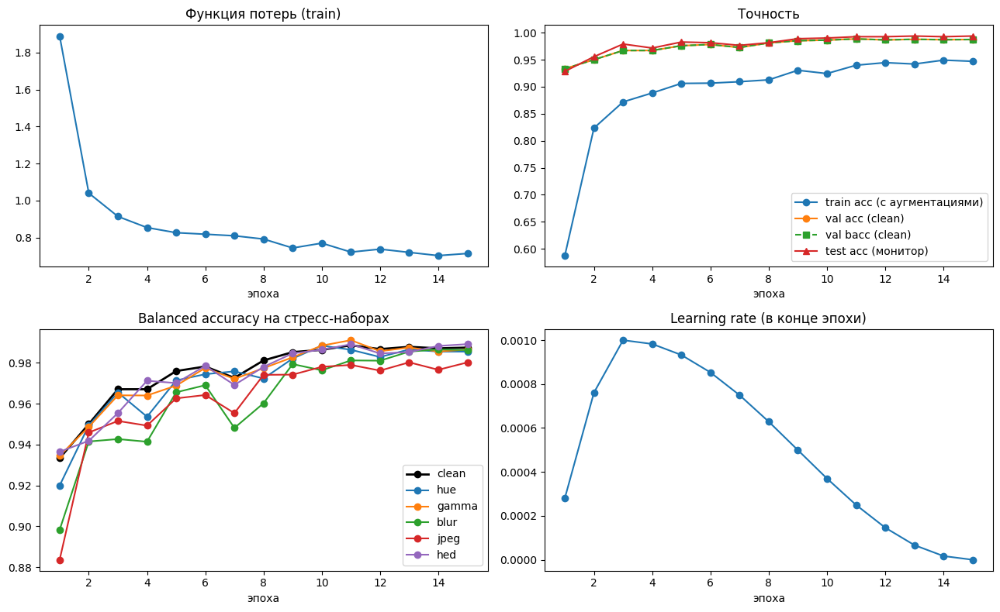

модель 2: loss в конце 0.7178, test-monitor acc 0.9901
модель 3: loss в конце 0.7189, test-monitor acc 0.9901


In [64]:
# #LBL6: графики обучения первой модели (у нее есть валидация)
hist = model.history or load_history()
if hist is not None:
    plot_history(hist, RESULTS_DIR / 'training_curves.png')
else:
    print('история обучения недоступна (модель загружена, обучение было в другой сессии)')

# остальные модели ансамбля учились на всем train, для них есть только loss и тест-монитор
for m, h in enumerate(model.histories[1:], start=2):
    mon = h['monitor'][-1]
    mon_txt = '' if mon is None else f', test-monitor acc {mon[0]:.4f}'
    print(f'модель {m}: loss в конце {h["train_loss"][-1]:.4f}{mon_txt}')

класс   чувствит.  специфич.
ADI        0.9960     1.0000
BACK       1.0000     0.9998
DEB        0.9800     0.9988
LYM        1.0000     1.0000
MUC        0.9920     0.9985
MUS        0.9940     0.9985
NORM       0.9880     0.9998
STR        0.9840     0.9962
TUM        0.9940     0.9995
среднее     0.9920     0.9990


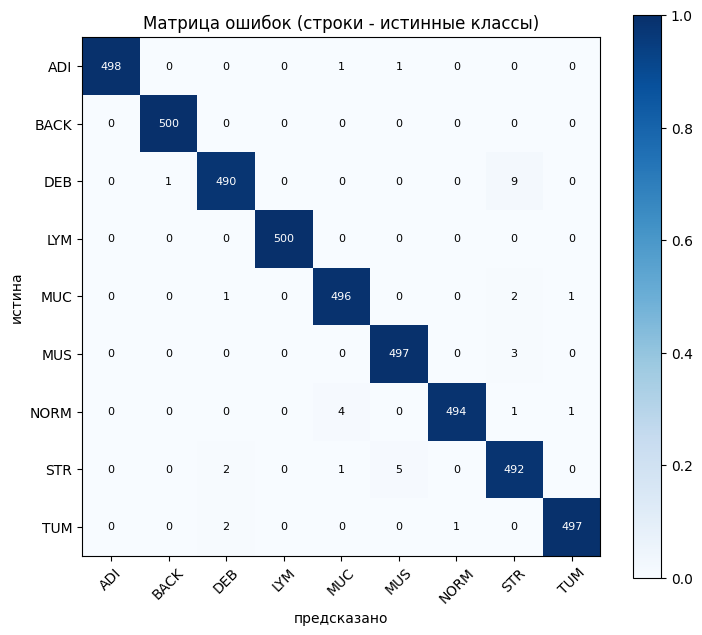

In [65]:
# #LBL8: матрица ошибок, чувствительность и специфичность на тесте
if 'pred_2' not in globals():
    pred_2 = model.test_on_dataset(d_test)
y_true_test = np.asarray(d_test.labels)[:len(pred_2)]

cm, rows = sensitivity_specificity(y_true_test, pred_2)
print_sens_spec(rows)
plot_confusion(cm, RESULTS_DIR / 'confusion_matrix_test.png')

предсказания сохранены: /content/drive/MyDrive/prak_nn_1/results/test_predictions.csv
ошибок: 36 из 4500
картинка с ошибками сохранена: /content/drive/MyDrive/prak_nn_1/results/test_errors.png


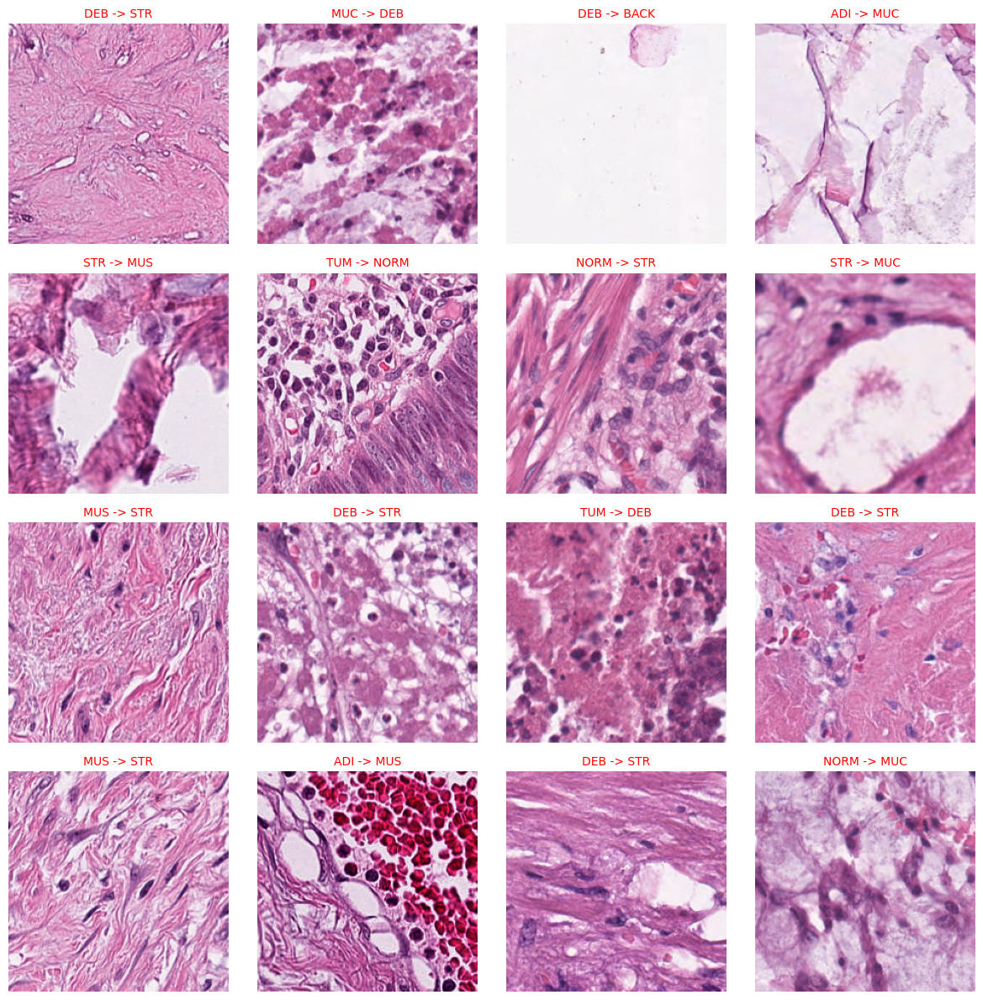

In [66]:
# #LBL10: сохраняю предсказания в csv и рисую ошибки
save_predictions_csv(RESULTS_DIR / 'test_predictions.csv', y_true_test, pred_2)
show_errors(d_test, y_true_test, pred_2, RESULTS_DIR / 'test_errors.png')

In [67]:
# #LBL13: модель на чистой и стресс-валидации
# смотрю только первую модель ансамбля, потому что остальные видели эти картинки при обучении
_, final_eval_loaders = make_split_loaders(d_train)
final_val_results = evaluate_loaders(model.nets[0], final_eval_loaders, device)
print('robust score:', round(robust_score(final_val_results), 4))

набор        acc    bacc
clean     0.9885  0.9885
hue       0.9860  0.9863
gamma     0.9910  0.9910
blur      0.9810  0.9811
jpeg      0.9790  0.9789
hed       0.9890  0.9890
robust score: 0.9869


Результат работы пайплайна обучения и тестирования выше тоже будет оцениваться. Поэтому не забудьте присылать на проверку ноутбук с выполнеными ячейками кода с демонстрациями метрик обучения, графиками и т.п. В этом пайплайне Вам необходимо продемонстрировать работу всех реализованных дополнений, улучшений и т.п.

<font color="red">
Настоятельно рекомендуется после получения пайплайна с полными результатами обучения экспортировать ноутбук в pdf (файл -> печать) и прислать этот pdf вместе с самим ноутбуком.
</font>

### Тестирование модели на других наборах данных

Ваша модель должна поддерживать тестирование на других наборах данных. Для удобства, Вам предоставляется набор данных test_tiny, который представляет собой малую часть (2% изображений) набора test. Ниже приведен фрагмент кода, который будет осуществлять тестирование для оценивания Вашей модели на дополнительных тестовых наборах данных.

<font color="red">
Прежде чем отсылать задание на проверку, убедитесь в работоспособности фрагмента кода ниже.
</font>


In [68]:
final_model = Model()
final_model.load('best')
d_test_tiny = Dataset('test_tiny')
pred = final_model.test_on_dataset(d_test_tiny)
Metrics.print_all(d_test_tiny.labels, pred, 'test-tiny')

Downloading...
From (original): https://drive.google.com/uc?id=1u2AvLjDzHzJ83Kiw5i6DEdfFXGEExBxX
From (redirected): https://drive.google.com/uc?id=1u2AvLjDzHzJ83Kiw5i6DEdfFXGEExBxX&confirm=t&uuid=f7550e4a-036d-4de2-afb3-8f0083353904
To: /content/best.pt
100%|██████████| 49.0M/49.0M [00:00<00:00, 175MB/s]


Модель загружена из best.pt (моделей в ансамбле: 3).


Downloading...
From: https://drive.google.com/uc?id=1viiB0s041CNsAK4itvX8PnYthJ-MDnQc
To: /content/test_tiny.npz
100%|██████████| 10.6M/10.6M [00:00<00:00, 28.0MB/s]

Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.


  0%|          | 0/90 [00:00<?, ?it/s]

metrics for test-tiny:
	 accuracy 0.9889:
	 balanced accuracy 0.9889:


In [69]:
# показываю что работает загрузка весов с конкретной эпохи и дообучение
# (чекпоинты лежат на моем диске, поэтому только когда было обучение)
if not EVALUATE_ONLY:
    m_demo = Model()
    m_demo.load_checkpoint(5) # #LBL4: веса 5-й эпохи первой модели
    Metrics.print_all(d_test_tiny.labels, m_demo.test_on_dataset(d_test_tiny), 'test-tiny, эпоха 5')
    m_demo.finetune(ds_tiny, epochs=1) # #LBL12: дообучение на другом наборе (train_tiny)
    Metrics.print_all(d_test_tiny.labels, m_demo.test_on_dataset(d_test_tiny), 'test-tiny, после дообучения')

Загружены веса эпохи 5: /content/drive/MyDrive/prak_nn_1/ckpt/m0/epoch_5.pt


  0%|          | 0/90 [00:00<?, ?it/s]

metrics for test-tiny, эпоха 5:
	 accuracy 0.9667:
	 balanced accuracy 0.9667:


  0%|          | 0/11 [00:00<?, ?it/s]

эпоха  1/1 | loss 0.8268 | train acc 0.8991 | val bacc 0.9852 | stress bacc 0.9852 | score 0.9852 | lr 3.15e-06 | 9 с


  0%|          | 0/90 [00:00<?, ?it/s]

metrics for test-tiny, после дообучения:
	 accuracy 0.9778:
	 balanced accuracy 0.9778:


Google Drive пока не отключаем: примеры архивов ниже пишут файлы на Диск. Отключение стоит в последней ячейке.


In [70]:
# Диск остаётся примонтированным до последней ячейки.


---
# Дополнительные "полезности"

Ниже приведены примеры использования различных функций и библиотек, которые могут быть полезны при выполнении данного практического задания.

### Измерение времени работы кода

Измерять время работы какой-либо функции можно легко и непринужденно при помощи функции timeit из соответствующего модуля:

In [71]:
import timeit

def factorial(n):
    res = 1
    for i in range(1, n + 1):
        res *= i
    return res


def f():
    return factorial(n=1000)

n_runs = 128
print(f'Function f is caluclated {n_runs} times in {timeit.timeit(f, number=n_runs)}s.')

Function f is caluclated 128 times in 0.030056671999773243s.


### Scikit-learn

Для использования "классических" алгоритмов машинного обучения рекомендуется использовать библиотеку scikit-learn (https://scikit-learn.org/stable/). Пример классификации изображений цифр из набора данных MNIST при помощи классификатора SVM:

Classification report for classifier SVC(gamma=0.001):
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.99      0.97      0.98        91
           2       0.99      0.99      0.99        86
           3       0.98      0.87      0.92        91
           4       0.99      0.96      0.97        92
           5       0.95      0.97      0.96        91
           6       0.99      0.99      0.99        91
           7       0.96      0.99      0.97        89
           8       0.94      1.00      0.97        88
           9       0.93      0.98      0.95        92

    accuracy                           0.97       899
   macro avg       0.97      0.97      0.97       899
weighted avg       0.97      0.97      0.97       899




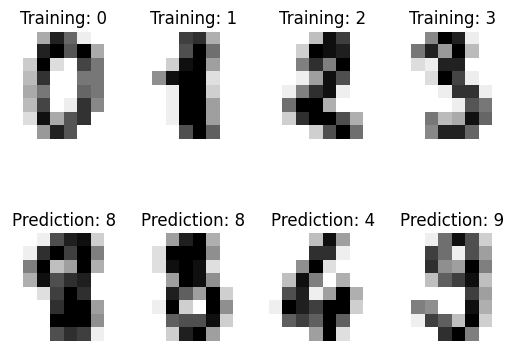

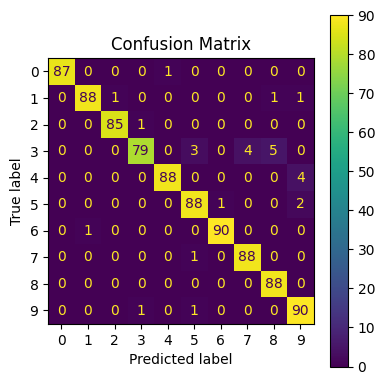

In [72]:
# Standard scientific Python imports
import matplotlib.pyplot as plt

# Import datasets, classifiers and performance metrics
from sklearn import datasets, svm, metrics
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# The digits dataset
digits = datasets.load_digits()

# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.
_, axes = plt.subplots(2, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes[0, :], images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)

# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Create a classifier: a support vector classifier
classifier = svm.SVC(gamma=0.001)

# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False)

# We learn the digits on the first half of the digits
classifier.fit(X_train, y_train)

# Now predict the value of the digit on the second half:
predicted = classifier.predict(X_test)

images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes[1, :], images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

# Матрица ошибок + визуализация в новом API
cm = metrics.confusion_matrix(y_test, predicted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=classifier.classes_)

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax)
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Scikit-image

Реализовывать различные операции для работы с изображениями можно как самостоятельно, работая с массивами numpy, так и используя специализированные библиотеки, например, scikit-image (https://scikit-image.org/). Ниже приведен пример использования Canny edge detector.

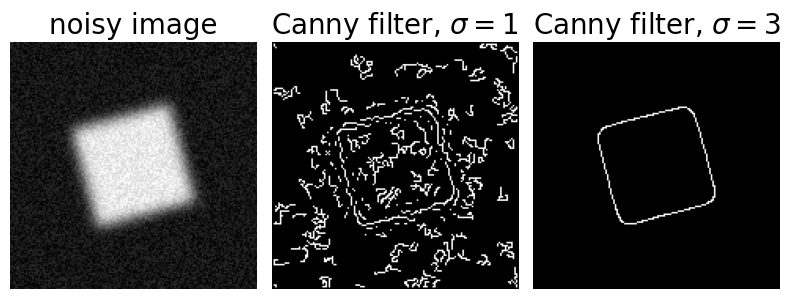

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from skimage import feature


# Generate noisy image of a square
im = np.zeros((128, 128))
im[32:-32, 32:-32] = 1

im = ndi.rotate(im, 15, mode='constant')
im = ndi.gaussian_filter(im, 4)
im += 0.2 * np.random.random(im.shape)

# Compute the Canny filter for two values of sigma
edges1 = feature.canny(im)
edges2 = feature.canny(im, sigma=3)

# display results
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(8, 3),
                                    sharex=True, sharey=True)

ax1.imshow(im, cmap=plt.cm.gray)
ax1.axis('off')
ax1.set_title('noisy image', fontsize=20)

ax2.imshow(edges1, cmap=plt.cm.gray)
ax2.axis('off')
ax2.set_title(r'Canny filter, $\sigma=1$', fontsize=20)

ax3.imshow(edges2, cmap=plt.cm.gray)
ax3.axis('off')
ax3.set_title(r'Canny filter, $\sigma=3$', fontsize=20)

fig.tight_layout()

plt.show()

### Tensorflow 2

Для создания и обучения нейросетевых моделей можно использовать фреймворк глубокого обучения Tensorflow 2. Ниже приведен пример простейшей нейроной сети, использующейся для классификации изображений из набора данных MNIST.

In [74]:
# Install TensorFlow

import tensorflow as tf

mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

demo_mnist_model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10, activation='softmax')
])

demo_mnist_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

demo_mnist_model.fit(x_train, y_train, epochs=5)

demo_mnist_model.evaluate(x_test,  y_test, verbose=2)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9162 - loss: 0.2894
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9577 - loss: 0.1410
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9682 - loss: 0.1057
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9736 - loss: 0.0865
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9762 - loss: 0.0757
313/313 - 3s - 8ms/step - accuracy: 0.9771 - loss: 0.0729


[0.07294780015945435, 0.9771000146865845]

<font color="red">
Для эффективной работы с моделями глубокого обучения убедитесь в том, что в текущей среде Google Colab используется аппаратный ускоритель GPU или TPU. Для смены среды выберите "среда выполнения" -> "сменить среду выполнения".
</font>

Большое количество туториалов и примеров с кодом на Tensorflow 2 можно найти на официальном сайте https://www.tensorflow.org/tutorials?hl=ru.

Также, Вам может понадобиться написать собственный генератор данных для Tensorflow 2. Скорее всего он будет достаточно простым, и его легко можно будет реализовать, используя официальную документацию TensorFlow 2. Но, на всякий случай (если не удлось сразу разобраться или хочется вникнуть в тему более глубоко), можете посмотреть следующий отличный туториал: https://stanford.edu/~shervine/blog/keras-how-to-generate-data-on-the-fly.

### PyTorch

Готовой сети и цикла обучения в шаблоне нет: это часть задания. Данные для PyTorch берёт класс `HistologyTorchDataset` выше. Ниже — ссылки на документацию.


In [75]:
print(
    "Для PyTorch используйте класс HistologyTorchDataset из ячеек выше. "
    "Ссылки на документацию — в следующей ячейке."
)


Для PyTorch используйте класс HistologyTorchDataset из ячеек выше. Ссылки на документацию — в следующей ячейке.


### Дополнительные ресурсы по PyTorch

- **Официальные туториалы PyTorch** — https://pytorch.org/tutorials/  
- **“Deep Learning with PyTorch: 60-Minute Blitz”** — https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html  
- **Transfer Learning for Computer Vision** — https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html  
- **PyTorch Get Started (установка)** — https://pytorch.org/get-started/locally/  
- **Dive into Deep Learning (D2L, глава PyTorch)** — https://d2l.ai/chapter_preliminaries/index.html  
- **Fast.ai — Practical Deep Learning for Coders** — https://course.fast.ai/  
- **Learn PyTorch.io (Zero to Mastery)** — https://www.learnpytorch.io/

### Numba

В некоторых ситуациях, при ручных реализациях графовых алгоритмов, выполнение многократных вложенных циклов for в python можно существенно ускорить, используя JIT-компилятор Numba (https://numba.pydata.org/).
Примеры использования Numba в Google Colab можно найти тут:
1. https://colab.research.google.com/github/cbernet/maldives/blob/master/numba/numba_cuda.ipynb
2. https://colab.research.google.com/github/evaneschneider/parallel-programming/blob/master/COMPASS_gpu_intro.ipynb

> Пожалуйста, если Вы решили использовать Numba для решения этого практического задания, еще раз подумайте, нужно ли это Вам, и есть ли возможность реализовать требуемую функциональность иным способом. Используйте Numba только при реальной необходимости.



### Работа с zip архивами в Google Drive

Запаковка и распаковка zip архивов может пригодиться при сохранении и загрузки Вашей модели. Ниже приведен фрагмент кода, иллюстрирующий помещение нескольких файлов в zip архив с последующим чтением файлов из него. Все действия с директориями, файлами и архивами должны осущетвляться с примонтированным Google Drive.


Создадим 2 изображения, поместим их в директорию tmp внутри PROJECT_DIR, запакуем директорию tmp в архив tmp.zip.

In [76]:
PROJECT_DIR = "prak_nn_1"
arr1 = np.random.rand(100, 100, 3) * 255
arr2 = np.random.rand(100, 100, 3) * 255

img1 = Image.fromarray(arr1.astype('uint8'))
img2 = Image.fromarray(arr2.astype('uint8'))

p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
Path(p, "tmp").mkdir(parents=True, exist_ok=True)

img1.save(str(Path(p) / "tmp" / "img1.png"))
img2.save(str(Path(p) / "tmp" / "img2.png"))

%cd $p
!zip -r "tmp.zip" "tmp"


/content/drive/MyDrive/prak_nn_1
updating: tmp/ (stored 0%)
updating: tmp/img1.png (stored 0%)
updating: tmp/img2.png (stored 0%)


Распакуем архив tmp.zip в директорию tmp2 в PROJECT_DIR. Теперь внутри директории tmp2 содержится директория tmp, внутри которой находятся 2 изображения.

In [82]:
p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
%cd $p
!unzip -uq "tmp.zip" -d "tmp2"
%cd /content


/content/drive/MyDrive/prak_nn_1
replace tmp2/tmp/img1.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace tmp2/tmp/img2.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
/content


Отмонтировать Google Drive.


In [83]:
drive.flush_and_unmount()
